In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/home-data-for-ml-course/sample_submission.csv
/kaggle/input/competitions/home-data-for-ml-course/sample_submission.csv.gz
/kaggle/input/competitions/home-data-for-ml-course/train.csv.gz
/kaggle/input/competitions/home-data-for-ml-course/data_description.txt
/kaggle/input/competitions/home-data-for-ml-course/test.csv.gz
/kaggle/input/competitions/home-data-for-ml-course/train.csv
/kaggle/input/competitions/home-data-for-ml-course/test.csv


In [2]:
#Load training and test datasets

train = pd.read_csv('/kaggle/input/competitions/home-data-for-ml-course/train.csv')
test = pd.read_csv('/kaggle/input/competitions/home-data-for-ml-course/test.csv')

print ("Train shape"), train.shape
print ("Test shape"), test.shape 

Train shape
Test shape


(None, (1459, 80))

<Axes: ylabel='Frequency'>

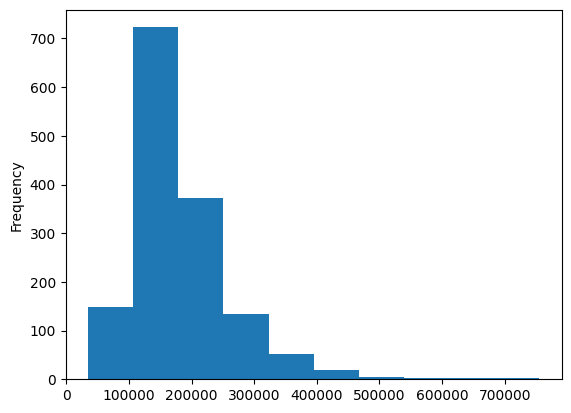

In [3]:
#plot histogram of sales prices
y = train.SalePrice

y.plot(kind='hist')

In [4]:
#Create feature set
features = ["GrLivArea", "YearBuilt", "BedroomAbvGr", "FullBath", "LotArea"]
X = train[features]
X.head()

,GrLivArea,YearBuilt,BedroomAbvGr,FullBath,LotArea
0,1710,2003,3,2,8450
1,1262,1976,3,2,9600
2,1786,2001,3,2,11250
3,1717,1915,3,1,9550
4,2198,2000,4,2,14260


In [5]:
#create the model
from sklearn.tree import DecisionTreeRegressor

#random_state=1 ensures the same results across runs
housing_model = DecisionTreeRegressor(random_state=1)

#fit model
housing_model.fit(X, y)


DecisionTreeRegressor(random_state=1)

In [6]:
print("Making predictions for the following 5 houses")
print(X.head())

print("The precitions are")
print(housing_model.predict(X.head()))

Making predictions for the following 5 houses
   GrLivArea  YearBuilt  BedroomAbvGr  FullBath  LotArea
0       1710       2003             3         2     8450
1       1262       1976             3         2     9600
2       1786       2001             3         2    11250
3       1717       1915             3         1     9550
4       2198       2000             4         2    14260
The precitions are
[208500. 181500. 223500. 140000. 250000.]


In [7]:
from sklearn.metrics import mean_absolute_error

predicted_home_prices = housing_model.predict(X)

mean_absolute_error(y, predicted_home_prices)

73.31324200913242

In [8]:
from sklearn.model_selection import train_test_split

# split data into training and validation data, for both features and target 
# The split is based on a random number generator. Supplying a numeric value to
# the random_state argument guarantees we get the same split every time

train_X, val_X, train_y, val_y = train_test_split(X, y, random_state = 0)


In [9]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Build a Random Forest model
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=1
)

# Train on the training data
forest_model.fit(train_X, train_y)

# Predict house prices using unseen validation data
forest_predictions = forest_model.predict(val_X)

# Measure how far the predictions are from actual prices
forest_mae = mean_absolute_error(val_y, forest_predictions)

print("Random Forest MAE: $", round(forest_mae, 2))

Random Forest MAE: $ 23327.73


In [10]:

from sklearn.model_selection import train_test_split

# Select the house features
features = [
    'GrLivArea',
    'YearBuilt',
    'BedroomAbvGr',
    'FullBath',
    'LotArea'
]

X = train[features]
y = train['SalePrice']

# Split the data into training and validation sets
train_X, val_X, train_y, val_y = train_test_split(
    X, y, random_state=0
)

print("Training data ready!")


Training data ready!
